# Laboratory 08. Build an evidence package

**Prepared by Adrian Dunkley, Physicist, Climate Studies Group, Mona.**

This is a complete worked laboratory. Run every cell in order, then carry out the investigations. The default data are synthetic. Consult the matching lecture and [assessment brief](../ASSESSMENT.md).

In [1]:
# Prepared by Adrian Dunkley, Physicist, Climate Studies Group, Mona.
from pathlib import Path
import sys, subprocess
# Local runs discover the checkout. Colab fetches it only if it is absent.
roots = [Path.cwd(), *Path.cwd().parents, Path('/content/satellitedatahscourse')]
root = next((p for p in roots if (p/'python'/'eo_course.py').exists()), None)
if root is None:
    if 'google.colab' not in sys.modules:
        raise RuntimeError('Open this notebook inside the course repository.')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'requests', 'rasterio', 'scikit-learn'], check=True)
    subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/caribbeanai/satellitedatahscourse.git', '/content/satellitedatahscourse'], check=True)
    root = Path('/content/satellitedatahscourse')
sys.path.insert(0, str(root/'python'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import eo_course as eo
plt.rcParams.update({'figure.figsize': (9, 4), 'figure.facecolor': 'white'})
print(eo.CREDIT)
print('Default data: SYNTHETIC teaching examples, not observations of Jamaica.')


Prepared by Adrian Dunkley, Physicist, Climate Studies Group, Mona.
Default data: SYNTHETIC teaching examples, not observations of Jamaica.


## 1. Write an evidence ledger
 The worked track combines synthetic candidate-change area with hypothetical production assumptions. It is a scenario exercise. A student capstone must add independently chosen data or an original investigation and cannot submit the unchanged example as observed research.

In [2]:
ledger=pd.DataFrame([
    {'statement':'Candidate area','type':'synthetic derived output','source':'eo.synthetic_scene and declared change'},
    {'statement':'Farmland share','type':'hypothetical assumption','source':'teaching scenario; replace with applicable evidence'},
    {'statement':'Value per hectare','type':'hypothetical assumption','source':'teaching scenario; not a Jamaican market quote'},
    {'statement':'Recommendation','type':'student interpretation','source':'conditional on data quality and validation'}])
display(ledger)

           statement  ...                                             source
0     Candidate area  ...             eo.synthetic_scene and declared change
1     Farmland share  ...  teaching scenario; replace with applicable evi...
2  Value per hectare  ...     teaching scenario; not a Jamaican market quote
3     Recommendation  ...         conditional on data quality and validation

[4 rows x 3 columns]

## 2. Produce a small reproducible measurement
 The example uses known artificial loss, retains missing pixels and reports the candidate area. It reuses the measurement helper rather than copying its logic into a new spreadsheet.

   threshold  candidate_ha  observed_ha  unknown_ha  excluded_ha
0       -0.2         19.16         68.4        0.72        74.88

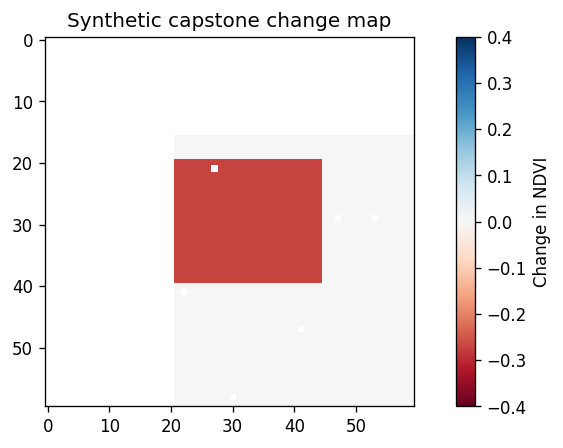

In [3]:
scene=eo.synthetic_scene(seed=42)
before,support=eo.median_composite(eo.normalized_difference(scene['nir'],scene['red']),eo.clear_mask(scene['scl']))
after=before.copy();after[20:40,20:45]-=.27
# Missing baseline pixels remain unknown; known low-index pixels are excluded.
eligible=(before>.4) | ~np.isfinite(before)
result=eo.changed_area(before,after,threshold=-.2,eligible=eligible)
candidate_ha=result['candidate_ha']
display(pd.DataFrame([{k:v for k,v in result.items() if k!='delta'}]))
plt.imshow(result['delta'],cmap='RdBu',vmin=-.4,vmax=.4)
plt.colorbar(label='Change in NDVI');plt.title('Synthetic capstone change map');plt.show()

## 3. Calculate scenario bounds with units
 Multiply hectares by assumed farmland share, annual production value (JMD/ha/year) and recovery duration (years). All inputs below are hypothetical. These are assumed forgone-production scenarios, not verified disaster costs or statistical confidence limits.

  scenario  farm_share  ...  candidate_ha  scenario_jmd
0      low         0.3  ...         19.16      287400.0
1  central         0.5  ...         19.16     1916000.0
2     high         0.7  ...         19.16     8047200.0

[3 rows x 6 columns]

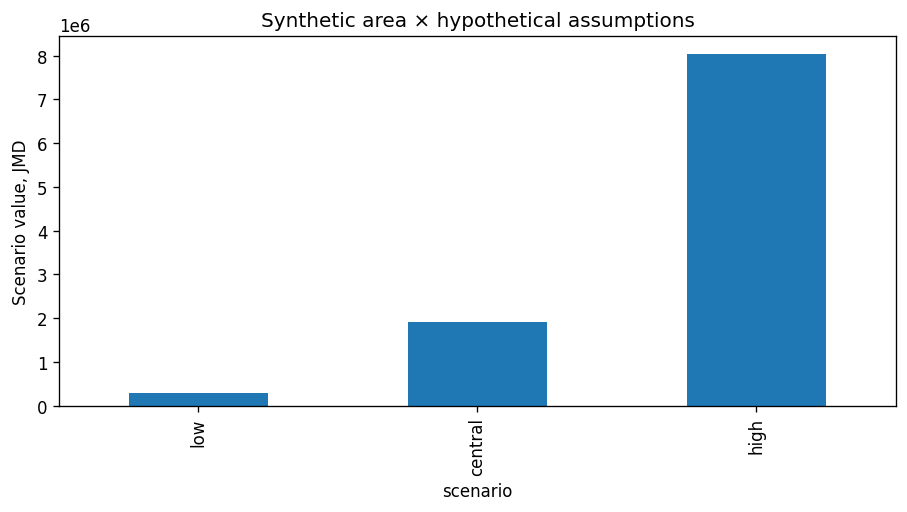

In [4]:
assumptions=pd.DataFrame([
    {'scenario':'low','farm_share':.3,'annual_jmd_per_ha':100_000,'recovery_years':.5},
    {'scenario':'central','farm_share':.5,'annual_jmd_per_ha':200_000,'recovery_years':1.0},
    {'scenario':'high','farm_share':.7,'annual_jmd_per_ha':300_000,'recovery_years':2.0}])
assumptions['candidate_ha']=candidate_ha
assumptions['scenario_jmd']=(assumptions.candidate_ha*assumptions.farm_share*
                             assumptions.annual_jmd_per_ha*assumptions.recovery_years)
display(assumptions)
assumptions.plot.bar(x='scenario',y='scenario_jmd',legend=False,
                      title='Synthetic area × hypothetical assumptions',ylabel='Scenario value, JMD')
plt.show()

## 4. Save the package and prove file identity
 Save the analysis table, evidence ledger, array and a manifest containing output hashes. Timestamps change on rerun; seeded numerical outputs should remain stable within the tested environment. A hash confirms bytes, not the correctness of a scientific conclusion.

In [5]:
out=root/'outputs'/'week4';out.mkdir(parents=True,exist_ok=True)
assumptions.to_csv(out/'synthetic_scenarios.csv',index=False)
ledger.to_csv(out/'evidence_ledger.csv',index=False)
np.save(out/'synthetic_change.npy',result['delta'])
files=[out/'synthetic_scenarios.csv',out/'evidence_ledger.csv',out/'synthetic_change.npy']
manifest=eo.write_manifest(out/'manifest.json','synthetic',
    {'generator':'eo.synthetic_scene','prices':'hypothetical classroom assumptions'},
    {'seed':42,'pixel_metres':20,'threshold':-.2,'eligibility':'before NDVI > 0.4; missing baseline retained as unknown'},files)
import hashlib
assert all(hashlib.sha256((out/p).read_bytes()).hexdigest()==digest
           for p,digest in manifest['outputs'].items())
display(manifest)

{'prepared_by': 'Prepared by Adrian Dunkley, Physicist, Climate Studies Group, Mona.', 'data_kind': 'synthetic', 'created_utc': '2026-10-25T05:37:50.986791+00:00', 'inputs': {'generator': 'eo.synthetic_scene', 'prices': 'hypothetical classroom assumptions'}, 'settings': {'seed': 42, 'pixel_metres': 20, 'threshold': -0.2, 'eligibility': 'before NDVI > 0.4; missing baseline retained as unknown'}, 'outputs': {'synthetic_scenarios.csv': '2fc7cd5a54285cd98a23d5b690f1697fc792003dbb95d4bd5410138b78742826', 'evidence_ledger.csv': 'bb6dd1c483ca0997b5a2259b53475cc8ba3dd88c945e18645f5729438c657903', 'synthetic_change.npy': '0a0a4a171e4443c6ce24399204d097887635466fe23d3c47c61c306d5d1b0804'}}

## 5. Failure review and fresh-run checklist
 Ask a peer to reproduce the area and name the denominator. Try an all-missing after image: candidate area should be zero *with zero observed area*, never evidence of no loss. Inspect the ledger and explain what additional field evidence could change your recommendation.

In [6]:
empty=eo.changed_area(before,np.full_like(before,np.nan))
assert empty['observed_ha']==0 and empty['candidate_ha']==0
print('No observations: no conclusion about presence or absence of loss.')
print('Submission needs an original question, evidence-backed inputs, validation and interpretation.')

No observations: no conclusion about presence or absence of loss.
Submission needs an original question, evidence-backed inputs, validation and interpretation.


## 6. Choose your project and present it
 Select the storm-change scenario, solar-site comparison, vegetation-per-resident analysis or forecast evaluation. Follow the track requirements in the assessment brief. Prepare five minutes covering question, method, main evidence, largest uncertainty and conditional recommendation. Include the notebook, data card, permitted outputs, manifest, sources and peer-review corrections.

## Before submitting

Restart the kernel and run all cells. Label synthetic and observed outputs separately. Include the source, dates, units, quality policy and unknown coverage in captions. See [verified sources](../SOURCES.md) and the [instructor guide](../instructor/GUIDE.md).

Prepared by Adrian Dunkley, Physicist, Climate Studies Group, Mona.